In [1]:
# this script reads and plots fog and cloud layers from wrf output 

# Gert-Jan Duine, ERI UCSB, September 2020
# gertjan.duine@gmail.com / duine@eri.ucsb.edu

import pandas as pd # pandas is more labeled tabular oriented. works well if headers are provided in files.
import numpy as np
import scipy as sp
import scipy.io
import netCDF4
from netCDF4 import Dataset
import wrf
import xarray as xr

# plotting features/packages
from cartopy import crs
from cartopy.feature import NaturalEarthFeature, COLORS
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

from mpl_toolkits.axes_grid1 import make_axes_locatable

import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
import matplotlib as mpl
import cartopy.crs as ccrs
from cartopy.feature import NaturalEarthFeature

from wrf import (to_np, getvar, smooth2d, get_cartopy, cartopy_xlim,
                 cartopy_ylim, latlon_coords, get_basemap)


In [2]:
# this is for standard plots
def draw_basemap():

    # Create figure
    fig = plt.figure(figsize=(10,7)) 

    # Add plot axes and draw basemap
    ax = fig.add_subplot(111, projection=mapcrs)
    ax.set_extent([lonmin,lonmax,latmin,latmax], crs=mapcrs)

    # xticks
    ax.set_xticks(dx, crs=mapcrs)      
    lon_formatter = LongitudeFormatter()
    ax.xaxis.set_major_formatter(lon_formatter)
    # yticks
    ax.set_yticks(dy, crs=mapcrs)
    lat_formatter = LatitudeFormatter()
    ax.yaxis.set_major_formatter(lat_formatter)
    # tick params
    ax.tick_params(direction='out', labelsize=12, length=5, pad=2, color='black')    

    # Map features
    ax.add_feature(cfeature.LAND, facecolor='0.9') 
    ax.add_feature(cfeature.BORDERS, edgecolor='0.1', linewidth=0.7)
    ax.add_feature(cfeature.COASTLINE, edgecolor='k', linewidth=1.0)
    ax.add_feature(cfeature.STATES, edgecolor='0.1', linewidth=0.7)
    
    return fig, ax


/home/voyager-sbarc/students/duine/miniconda3/envs/pyclivac/bin/python
3.3.2 0.17.0
cartopy axes created OK


/home/voyager-sbarc/students/duine/miniconda3/envs/pyclivac/lib/python3.8/site-packages/cartopy/mpl/geoaxes.py:387: MatplotlibDeprecationWarning: 
The 'inframe' parameter of draw() was deprecated in Matplotlib 3.3 and will be removed two minor releases later. Use Axes.redraw_in_frame() instead. If any parameter follows 'inframe', they should be passed as keyword, not positionally.
  return matplotlib.axes.Axes.draw(self, renderer=renderer,


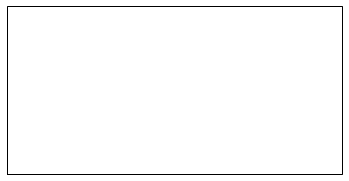

In [3]:
import sys, matplotlib, cartopy
print(sys.executable)
print(matplotlib.__version__, cartopy.__version__)

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
fig = plt.figure()
ax = fig.add_subplot(1,1,1, projection=ccrs.PlateCarree())
print("cartopy axes created OK")

In [4]:
# make new colormap for terrain elevation
# basically this is based on pre-defined colormap "terrain", but removed blue from low terrain elevation to have better
# distinction between real ocean and lower terrain
n=255 # nr of colors
x=0.25 # a cut-off value between 0 and 1. This value was decided after trial-error.
# 0.0170    0.5660    0.9660
lower = plt.cm.terrain(np.linspace(x,1,n)) # get terrain elevation map and "cut off"
colors=np.vstack((lower)) # not important here, but nice if you want to combine multiple arrays representing different colormaps
tmap=mpl.colors.LinearSegmentedColormap.from_list('map_white',colors) # creation of a new colormap 'tmap'


In [5]:
swex = scipy.io.loadmat('/home/voyager-sbarc/duine/sundowners/swex2022/instruments/SWEX2022_instrument_locations_BAMS_v2.mat')
swex

{'__header__': b'MATLAB 5.0 MAT-file, Platform: GLNXA64, Created on: Wed Oct 21 20:23:31 2026',
 '__version__': '1.0',
 '__globals__': [],
 'latsASOS': array([[34.217],
        [34.607],
        [34.667],
        [34.124],
        [34.201],
        [34.426],
        [34.894],
        [34.729]]),
 'latsCeilo': array([[34.56306  ],
        [34.4528   ],
        [34.6874   ],
        [34.60582  ],
        [34.5186111],
        [34.45508  ],
        [34.47679  ]]),
 'latsDrop': array([[34.51],
        [34.85],
        [34.25],
        [34.25],
        [34.92],
        [34.37],
        [34.25],
        [34.25],
        [34.25]]),
 'latsISFS': array([[34.4758272],
        [34.475615 ],
        [34.465763 ],
        [34.45924  ],
        [34.48284  ],
        [34.519034 ],
        [34.5302339],
        [34.5303416],
        [34.520205 ],
        [34.50053  ],
        [34.4893769],
        [34.5059778],
        [34.55756  ],
        [34.695    ],
        [34.731979 ],
        [34.599367 ],
   

In [11]:
# plot made with some inspiration from Marian de Orla-Barile

plot_crs=ccrs.PlateCarree()

# Download and create the states, land, and oceans using cartopy features
states = cfeature.NaturalEarthFeature(category='cultural', scale='10m',
                                              facecolor='none',
                                              name='admin_1_states_provinces_shp')
land = cfeature.NaturalEarthFeature(category='physical', name='land',
                                            scale='10m',
                                            facecolor='green')#facecolor='green')
ocean = cfeature.NaturalEarthFeature(category='physical', name='ocean',
                                             scale='10m',
                                             facecolor=[(0.0170, 0.5660, 0.9660)])#facecolor='blue')

# lakes =  cfeature.NaturalEarthFeature(category='physical', name='lakes',
#                                              scale='10m',
#                                              facecolor=[(0.0170, 0.5660, 0.9660)])#facecolor='blue')
# RIVERS_10m = cfeature.NaturalEarthFeature('physical', 'rivers_lake_centerlines', '10m',
#                                                  edgecolor=cfeature.COLORS['water'],
#                                                  facecolor='none')

# orange=[(1, 0.75, 0)]
orange=[(222/255, 88/255, 42/255)]
gold=[(255/255, 215/255, 0/255)]
yellow=[1, 1, 0]
#                                              facecolor=cfeature.COLORS['water'])

#a = addfile("/home/sandbox-wrf/real/WRF-4.0.1/test/real/wrfout_d02.nc","r") # where the actual file is

# folder definitions 
folder='/home/duine/reports/articles/SWEX_BAMS/' # path to store images
basefile='/home/voyager-sbarc/wrf/wrf422/WPS-4.2.2-duine/geo_em/LES_SYM_full/v4_200m/geo_em.d01.nc' # 200 m version
# basefile='/home/voyager-sbarc/wrf/wrf422/WPS-4.2.2-duine/geo_em/LES_SYM_full/v4/geo_em.d01.nc' # 50 m version

# some plotting definitions, outside any loop
lonmin=-120.3
lonmax=-119.4
latmin=34.35
latmax=34.8001
# Tickmark Locations
dxInt = np.arange(lonmin+0.2,lonmax,0.2)
dx = dxInt#[1:-1]
dy = np.arange(latmin+0.05,latmax,0.2) # plus 0.5 to start at 34.4

# biggest game change in speed for plotting is terrain elevation resolution. 
terLvls=np.arange(0,2100,100) # range for terrain elevation, lower limit, upper limit, resolution)

# start reading file
print('working on file ',basefile)
ncfile = netCDF4.Dataset(basefile)
ter = wrf.getvar(ncfile, "ter", timeidx=-1)
landmask=wrf.getvar(ncfile,"LANDMASK",timeidx=-1) # 1 for land, 0 for lakes
lu_index=wrf.getvar(ncfile,"LU_INDEX",timeidx=-1)
# lake=wrf.getvar(ncfile,'ISLAKE',timeidx=-1)

# U10,V10=getvar(ncfile,'uvmet10',t)
# Get the latitude and longitude points
lats, lons = latlon_coords(ter)
# Get the cartopy mapping object
cart_proj = get_cartopy(ter)

print('working on')

# Create a figure
fig = plt.figure(figsize=(12,9))
ax = fig.add_subplot(1,1,1,projection=plot_crs) 
# ax = fig.add_subplot(1,1,1,projection=cart_proj)  # why was this cart_proj??? This created a stupid error...

# terrain elevation by simple contours
# other map options: get_cmap("terrain"),#rainbow"),#"gist_earth"),
# terrain elevation by color grading and filled 
terrainContour=ax.contourf(to_np(lons), to_np(lats), to_np(ter), terLvls, cmap=tmap,
            transform=plot_crs) # terrain elevation map with color grading
#         terrainContourLine=ax_cld.contour(to_np(lons), to_np(lats), to_np(ter), terLvlsLine,
#                     colors='k',linewidths=0.5,transform=ccrs.PlateCarree()) # terrain elevation contours
print('terrain contours drawing done')
# Draw the oceans, land, and states
ax.add_feature(ocean)#,zorder=9)
# ax.add_feature(lakes,zorder = 10)
# ax.add_feature(RIVERS_10m)
# ax.contour(to_np(lons),to_np(lats),to_np(landmask), [0,1], linewidths=1, colors="k",crs=plot_crs,zorder=10) # this is also for lakes
# ax.scatter(to_np(lons),to_np(lats),to_np(lu_index==21),color='b',transform=plot_crs,zorder=10) # for lake water bodies: 21
# ax.pcolormesh(to_np(lons),to_np(lats), to_np(landmask==0), colors='b', crs=plot_crs, zorder=5)

ax.set_extent([lonmin,lonmax,latmin,latmax], crs=plot_crs)

# xticks
ax.set_xticks(dx, crs=plot_crs)
lon_formatter = LongitudeFormatter()
ax.xaxis.set_major_formatter(lon_formatter)
# yticks
ax.set_yticks(dy, crs=plot_crs)
lat_formatter = LatitudeFormatter()
ax.yaxis.set_major_formatter(lat_formatter)
# tick params
ax.tick_params(direction='out', labelsize=14, length=5, pad=2, color='black')   

ax.add_feature(states, linewidth=1.5, edgecolor="k")
# ax_cld.add_feature(cfeature.COASTLINE, edgecolor='k', linewidth=2.0,zorder=3)


############# add instruments on map ###########
# add the actual instruments
rs   =ax.scatter(swex['lonsRS'],   swex['latsRS']   ,marker='s',linewidth=2.0,facecolors='none',edgecolors='b',s=80,transform=plot_crs,zorder=10)
iss  =ax.scatter(swex['lonsISS'],  swex['latsISS']  ,marker='o',linewidth=2.0,facecolors='none',edgecolors=yellow,s=60,transform=plot_crs,zorder=10)
wprof=ax.scatter(swex['lonsWindProf449'],swex['latsWindProf449'],
                                                     marker='o',linewidth=2.0,facecolors='none',edgecolors=yellow,s=60,transform=plot_crs,zorder=10)
lidar=ax.scatter(swex['lonsLIDAR'],swex['latsLIDAR'],marker='^',linewidth=2.0,facecolors='none',edgecolors='r',s=60,transform=plot_crs,zorder=10)
isfs =ax.scatter(swex['lonsISFS'], swex['latsISFS'] ,marker='o',linewidth=2.0,facecolors='none',edgecolors='k',s=60,transform=plot_crs,zorder=10)
raws =ax.scatter(swex['lonsRAWS'], swex['latsRAWS'] ,marker='.',linewidth=1.5,facecolors='k',   edgecolors='k',s=60,transform=plot_crs,zorder=10)
asos =ax.scatter(swex['lonsASOS'], swex['latsASOS'] ,marker='.',linewidth=1.5,facecolors='k',   edgecolors='k',s=60,transform=plot_crs,zorder=10)
ceilo=ax.scatter(swex['lonsCeilo'],swex['latsCeilo'],marker='v',linewidth=1.5,facecolors='none',edgecolors='m',s=60,transform=plot_crs,zorder=10)

lidarIOP10=ax.scatter(-119.6593,34.4403,marker='^',linewidth=2.0,facecolors='none',
                      edgecolors='r',   s=60,transform=plot_crs,zorder=10)

isfs_lats=swex['latsISFS'] # put the swex isfs lats and lons in separate arrays to make loop work
isfs_lons=swex['lonsISFS']
# loop over the stations
# for ix in range(0,18):
#     if ix==12:
#         label_text = ax.annotate(str(ix+1),xy=(isfs_lons[ix],isfs_lats[ix]),xytext=((9,-8)), textcoords='offset points',
#                                 color='k', fontsize=10,fontweight='bold',
#                                  horizontalalignment='center', verticalalignment='center')
#     elif (ix==13 or ix==14):
#         label_text = ax.annotate(str(ix+1),xy=(isfs_lons[ix],isfs_lats[ix]),xytext=((-9,8)), textcoords='offset points',
#                                 color='k', fontsize=10,fontweight='bold',
#                                  horizontalalignment='center', verticalalignment='center')
#     elif (ix==4):
#         label_text = ax.annotate(str(ix+1),xy=(isfs_lons[ix],isfs_lats[ix]),xytext=((-7,6)), textcoords='offset points',
#                                 color='k', fontsize=10,fontweight='bold',
#                                  horizontalalignment='center', verticalalignment='center')
#     else: # the standard option
#         label_text = ax.annotate(str(ix+1),xy=(isfs_lons[ix],isfs_lats[ix]),xytext=((8,8)), textcoords='offset points',
#                                 color='k', fontsize=10,fontweight='bold',
#                                  horizontalalignment='center', verticalalignment='center')
            

#Define dictionary with font information for our labels
fontdict_text_labels    = {'fontsize': 14, 'fontweight': 'bold'}
#Define a list of tuples (label, lon, lat) for plotting on map
labels = [('Eastern Santa Ynez',-119.52,34.478), ('Mountains',-119.52,34.460),
          ('Western SYM',-119.90,34.52), 
          ('San Rafael Mountains',-119.643154,34.66493), 
          ('Pacific Ocean',-120.2,34.38)]

#For each label we have annotate that point on the map with the label name
for index, (label, lon, lat) in enumerate(labels):
    #Add in label text
    label_text = ax.annotate(label, xy=(lon,lat), xytext=((0,0)), color='k', textcoords='offset points', transform=plot_crs,
                             horizontalalignment='center', verticalalignment='center', **fontdict_text_labels)
    

# do santa ynez valley separately
textSYV=ax.annotate('Santa Ynez Valley', xy=(-119.9,34.55), xytext=((0,0)), color='k', 
                    textcoords='offset points', transform=plot_crs, rotation=-10,**fontdict_text_labels)
#                     horizontalalignment='center', verticalalignment='center', 


#Define a list of tuples (label, lon, lat) for plotting on map for cities
labelsCity=[('Santa Barbara',-119.71,34.425),
          ('Montecito',-119.63,34.405)]
fontdict_text_labelsCity   = {'fontsize': 10,'style':'italic'}

#For each label we have annotate that point on the map with the label name
for index, (label, lon, lat) in enumerate(labelsCity):
    #Add in label text
    label_text = ax.annotate(label, xy=(lon,lat), xytext=((0,0)), color='k', textcoords='offset points', transform=plot_crs,
                             horizontalalignment='center', verticalalignment='center', **fontdict_text_labelsCity)

    #Add text effect to label
    #https://matplotlib.org/3.2.1/tutorials/advanced/patheffects_guide.html
#     label_text.set_path_effects([path_effects.Stroke(linewidth=2, foreground='k'), path_effects.Normal()])



# add legend
ax.legend([lidar,isfs,raws,rs,iss,ceilo],['lidar','ISFS','RAWS/ASOS','Radiosonde','449/915 MHz','ceilometer'],
          loc='upper left', markerscale=1.25, handletextpad=0.4,facecolor='gray',framealpha=0.5,edgecolor='k')




# Add a color bar with axis divider
# https://matplotlib.org/stable/gallery/axes_grid1/demo_colorbar_with_axes_divider.html
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='2%', pad=0.2, axes_class=plt.Axes)
cbar=fig.colorbar(terrainContour,cax=cax, shrink=.5) # shrink is the colorbar size
cbar.set_label('Terrain elevation [m]', fontsize=12)
ax.set_ylabel('Latitude $^\circ$N',fontsize=14)
ax.set_xlabel('Longitude $^\circ$W',fontsize=14)


# cbar = plt.colorbar(topo_plot, cax=cax, orientation='vertical', spacing='uniform', drawedges=True, ticks=norm_boundaries[::2])
# cbar.set_label('Elevation (m)', color='k')


fig.show()
ax.set_title('SWEX domain and observations',fontsize=14)


# save figure
print('writing png')
fNameBase='Fig01_studyArea_200m'
fName=fNameBase+'.png'
fig.savefig(fName, bbox_inches='tight', dpi=300, facecolor='white', transparent=False)
del fName
# print('writing tif')
# fName=fNameBase+'.tif'
# fig.savefig(fName, bbox_inches='tight', dpi=300)
# del fName
# print('writing pdf')
# fName=fNameBase+'.pdf'
# fig.savefig(fName, bbox_inches='tight', dpi=100)

fig.clf() # close figure
plt.close() # close figure

del cbar # 

del ax,fName,terrainContour # 

del ter



working on file  /home/voyager-sbarc/wrf/wrf422/WPS-4.2.2-duine/geo_em/LES_SYM_full/v4_200m/geo_em.d01.nc
working on
terrain contours drawing done
writing png


NameError: name 'fName' is not defined

In [7]:
# SCE stations surrounding the SBBG lidar (-119.70871, 34.45508), IOP10 template (Fig. S5)
# stid: (lon, lat, elevation_m)
SCE_SBBG = {
    'SE244': (-119.71270, 34.46434, 298.7),   # upper, N of SBBG, dry downslope flow (980 ft)
    'SE505': (-119.69512, 34.44555, 202.4),   # upper, E of SBBG, dry downslope flow (664 ft)
    'SE509': (-119.71341, 34.45016, 182.3),   # lower, moist intrusion (598 ft)
    'SE502': (-119.70763, 34.44120, 152.4),   # lower, moist intrusion (500 ft)
    'SE766': (-119.71111, 34.43625,  80.2),   # marine air throughout (263 ft)
}

In [6]:
swex['lonsLIDAR']
swex['stRAWS'][0, 12][0]
swex['lonsRAWS'][12,0]

-119.626

In [9]:
# plot made with some inspiration from Marian de Orla-Barile

plot_crs=ccrs.PlateCarree()

# Download and create the states, land, and oceans using cartopy features
states = cfeature.NaturalEarthFeature(category='cultural', scale='10m',
                                              facecolor='none',
                                              name='admin_1_states_provinces_shp')
land = cfeature.NaturalEarthFeature(category='physical', name='land',
                                            scale='10m',
                                            facecolor='green')#facecolor='green')
ocean = cfeature.NaturalEarthFeature(category='physical', name='ocean',
                                             scale='10m',
                                             facecolor=[(0.0170, 0.5660, 0.9660)])#facecolor='blue')

# lakes =  cfeature.NaturalEarthFeature(category='physical', name='lakes',
#                                              scale='10m',
#                                              facecolor=[(0.0170, 0.5660, 0.9660)])#facecolor='blue')
# RIVERS_10m = cfeature.NaturalEarthFeature('physical', 'rivers_lake_centerlines', '10m',
#                                                  edgecolor=cfeature.COLORS['water'],
#                                                  facecolor='none')

# orange=[(1, 0.75, 0)]
orange=[(222/255, 88/255, 42/255)]
gold=[(255/255, 215/255, 0/255)]
yellow=[1, 1, 0]
#                                              facecolor=cfeature.COLORS['water'])

#a = addfile("/home/sandbox-wrf/real/WRF-4.0.1/test/real/wrfout_d02.nc","r") # where the actual file is

# folder definitions 
folder='/home/duine/reports/articles/SWEX_BAMS/' # path to store images
basefile='/home/voyager-sbarc/wrf/wrf422/WPS-4.2.2-duine/geo_em/LES_SYM_full/v4_200m/geo_em.d01.nc' # 200 m version
# basefile='/home/voyager-sbarc/wrf/wrf422/WPS-4.2.2-duine/geo_em/LES_SYM_full/v4/geo_em.d01.nc' # 50 m version

# some plotting definitions, outside any loop
lonmin=-120.3
lonmax=-119.4
latmin=34.35
latmax=34.8001
# Tickmark Locations
dxInt = np.arange(lonmin+0.2,lonmax,0.2)
dx = dxInt#[1:-1]
dy = np.arange(latmin+0.05,latmax,0.2) # plus 0.5 to start at 34.4

# biggest game change in speed for plotting is terrain elevation resolution. 
terLvls=np.arange(0,2100,100) # range for terrain elevation, lower limit, upper limit, resolution)

# start reading file
print('working on file ',basefile)
ncfile = netCDF4.Dataset(basefile)
ter = wrf.getvar(ncfile, "ter", timeidx=-1)
landmask=wrf.getvar(ncfile,"LANDMASK",timeidx=-1) # 1 for land, 0 for lakes
lu_index=wrf.getvar(ncfile,"LU_INDEX",timeidx=-1)
# lake=wrf.getvar(ncfile,'ISLAKE',timeidx=-1)

# U10,V10=getvar(ncfile,'uvmet10',t)
# Get the latitude and longitude points
lats, lons = latlon_coords(ter)
# Get the cartopy mapping object
cart_proj = get_cartopy(ter)

print('working on')

# Create a figure
fig = plt.figure(figsize=(12,9))
ax = fig.add_subplot(1,1,1,projection=plot_crs) 
# ax = fig.add_subplot(1,1,1,projection=cart_proj)  # why was this cart_proj??? This created a stupid error...

# terrain elevation by simple contours
# other map options: get_cmap("terrain"),#rainbow"),#"gist_earth"),
# terrain elevation by color grading and filled 
terrainContour=ax.contourf(to_np(lons), to_np(lats), to_np(ter), terLvls, cmap=tmap,
            transform=plot_crs) # terrain elevation map with color grading
#         terrainContourLine=ax_cld.contour(to_np(lons), to_np(lats), to_np(ter), terLvlsLine,
#                     colors='k',linewidths=0.5,transform=ccrs.PlateCarree()) # terrain elevation contours
print('terrain contours drawing done')
# Draw the oceans, land, and states
ax.add_feature(ocean)#,zorder=9)
# ax.add_feature(lakes,zorder = 10)
# ax.add_feature(RIVERS_10m)
# ax.contour(to_np(lons),to_np(lats),to_np(landmask), [0,1], linewidths=1, colors="k",crs=plot_crs,zorder=10) # this is also for lakes
# ax.scatter(to_np(lons),to_np(lats),to_np(lu_index==21),color='b',transform=plot_crs,zorder=10) # for lake water bodies: 21
# ax.pcolormesh(to_np(lons),to_np(lats), to_np(landmask==0), colors='b', crs=plot_crs, zorder=5)

ax.set_extent([lonmin,lonmax,latmin,latmax], crs=plot_crs)

# xticks
ax.set_xticks(dx, crs=plot_crs)
lon_formatter = LongitudeFormatter()
ax.xaxis.set_major_formatter(lon_formatter)
# yticks
ax.set_yticks(dy, crs=plot_crs)
lat_formatter = LatitudeFormatter()
ax.yaxis.set_major_formatter(lat_formatter)
# tick params
ax.tick_params(direction='out', labelsize=14, length=5, pad=2, color='black')   

ax.add_feature(states, linewidth=1.5, edgecolor="k")
# ax_cld.add_feature(cfeature.COASTLINE, edgecolor='k', linewidth=2.0,zorder=3)


############# add instruments on map ###########
# add the actual instruments
# rs   =ax.scatter(swex['lonsRS'],   swex['latsRS']   ,marker='s',linewidth=2.0,facecolors='none',edgecolors='b',s=80,transform=plot_crs,zorder=10)
# iss  =ax.scatter(swex['lonsISS'],  swex['latsISS']  ,marker='o',linewidth=2.0,facecolors='none',edgecolors=yellow,s=60,transform=plot_crs,zorder=10)
# wprof=ax.scatter(swex['lonsWindProf449'],swex['latsWindProf449'],
#                                                      marker='o',linewidth=2.0,facecolors='none',edgecolors=yellow,s=60,transform=plot_crs,zorder=10)
# isfs =ax.scatter(swex['lonsISFS'], swex['latsISFS'] ,marker='o',linewidth=2.0,facecolors='none',edgecolors='k',s=60,transform=plot_crs,zorder=10)

# asos =ax.scatter(swex['lonsASOS'], swex['latsASOS'] ,marker='.',linewidth=1.5,facecolors='k',   edgecolors='k',s=60,transform=plot_crs,zorder=10)
# ceilo=ax.scatter(swex['lonsCeilo'],swex['latsCeilo'],marker='v',linewidth=1.5,facecolors='none',edgecolors='m',s=60,transform=plot_crs,zorder=10)

lidarIOP10=ax.scatter(-119.6593,34.4403,marker='^',linewidth=3.0,facecolors='none',
                      edgecolors='r',   s=150,transform=plot_crs,zorder=10)
lidar=ax.scatter(swex['lonsLIDAR'][0],swex['latsLIDAR'][0],marker='^',linewidth=3.0,facecolors='none',edgecolors='r',s=150,transform=plot_crs,zorder=10)
lidar=ax.scatter(swex['lonsLIDAR'][3],swex['latsLIDAR'][3],marker='^',linewidth=3.0,facecolors='none',edgecolors='r',s=150,transform=plot_crs,zorder=10)

# raws station MOIC1 id 12
# raws =ax.scatter(swex['lonsRAWS'][12,0], swex['latsRAWS'][12,0] ,marker='.',linewidth=1.5,facecolors='k',   edgecolors='k',s=60,transform=plot_crs,zorder=10
# raws station SBVC1 id 18                
raws =ax.scatter(swex['lonsRAWS'][18,0], swex['latsRAWS'][18,0] ,marker='x',linewidth=1.5,facecolors='k',   edgecolors='k',s=60,transform=plot_crs,zorder=10)



lons, lats, _ = zip(*SCE_SBBG.values())
sce = ax.scatter(lons, lats, marker='.', linewidth=1.5, facecolors='k', edgecolors='k',
                 s=40, transform=plot_crs, zorder=10)



# isfs_lats=swex['latsISFS'] # put the swex isfs lats and lons in separate arrays to make loop work
# isfs_lons=swex['lonsISFS']
            

#Define dictionary with font information for our labels
fontdict_text_labels    = {'fontsize': 14, 'fontweight': 'bold'}
#Define a list of tuples (label, lon, lat) for plotting on map
labels = [('SBCFD-HQ',-119.820,34.470),
          ('Botanic',-119.71,34.493), ('Gardens',-119.71,34.475),
          ('MFS-2',-119.61,34.432)]

#For each label we have annotate that point on the map with the label name
for index, (label, lon, lat) in enumerate(labels):
    #Add in label text
    label_text = ax.annotate(label, xy=(lon,lat), xytext=((0,0)), color='k', textcoords='offset points', transform=plot_crs,
                             horizontalalignment='center', verticalalignment='center', **fontdict_text_labels)




#Define a list of tuples (label, lon, lat) for plotting on map for cities
labelsCity=[('Santa Barbara',-119.71,34.425),
          ('Montecito',-119.63,34.405)]
fontdict_text_labelsCity   = {'fontsize': 10,'style':'italic'}

#For each label we have annotate that point on the map with the label name
for index, (label, lon, lat) in enumerate(labelsCity):
    #Add in label text
    label_text = ax.annotate(label, xy=(lon,lat), xytext=((0,0)), color='k', textcoords='offset points', transform=plot_crs,
                             horizontalalignment='center', verticalalignment='center', **fontdict_text_labelsCity)


# now a different for geographic annotations (not bold)
fontdict_text_labelsGeo    = {'fontsize': 14, 'style': 'italic'}
#Define a list of tuples (label, lon, lat) for plotting on map
labelsGeo = [('Eastern Santa Ynez',-119.52,34.478), ('Mountains',-119.52,34.460),
          ('Western Santa Ynez Mountains',-120.0,34.52), 
          ('San Rafael Mountains',-119.643154,34.66493), 
          ('Pacific Ocean',-120.2,34.38)]

#For each label we have annotate that point on the map with the label name
for index, (label, lon, lat) in enumerate(labelsGeo):
    #Add in label text
    label_text = ax.annotate(label, xy=(lon,lat), xytext=((0,0)), color='k', textcoords='offset points', transform=plot_crs,
                             horizontalalignment='center', verticalalignment='center', **fontdict_text_labelsGeo)


# do santa ynez valley separately
textSYV=ax.annotate('Santa Ynez Valley', xy=(-119.9,34.55), xytext=((0,0)), color='k', 
                    textcoords='offset points', transform=plot_crs, rotation=-10,**fontdict_text_labelsGeo)
#                     horizontalalignment='center', verticalalignment='center', 



    #Add text effect to label
    #https://matplotlib.org/3.2.1/tutorials/advanced/patheffects_guide.html
#     label_text.set_path_effects([path_effects.Stroke(linewidth=2, foreground='k'), path_effects.Normal()])



# add legend
ax.legend([lidar,raws,sce],['lidar','SBVC1','SCE'],
          loc='upper left', markerscale=1.25, handletextpad=0.4,
          facecolor='gray',framealpha=0.5,edgecolor='k',fontsize=14)




# Add a color bar with axis divider
# https://matplotlib.org/stable/gallery/axes_grid1/demo_colorbar_with_axes_divider.html
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='2%', pad=0.2, axes_class=plt.Axes)
cbar=fig.colorbar(terrainContour,cax=cax, shrink=.5) # shrink is the colorbar size
cbar.set_label('Terrain elevation [m]', fontsize=12)
ax.set_ylabel('Latitude $^\circ$N',fontsize=14)
ax.set_xlabel('Longitude $^\circ$W',fontsize=14)


# cbar = plt.colorbar(topo_plot, cax=cax, orientation='vertical', spacing='uniform', drawedges=True, ticks=norm_boundaries[::2])
# cbar.set_label('Elevation (m)', color='k')


fig.show()
ax.set_title('SWEX domain and observations',fontsize=14)


# save figure
print('writing png')
fNameBase='Fig01_studyArea_200m_IOP10_only'
fName=fNameBase+'.png'
fig.savefig(fName, bbox_inches='tight', dpi=300, facecolor='white', transparent=False)
del fName

fig.clf() # close figure
plt.close() # close figure

del cbar # 

del ax,terrainContour # 

del ter
print('done')

working on file  /home/voyager-sbarc/wrf/wrf422/WPS-4.2.2-duine/geo_em/LES_SYM_full/v4_200m/geo_em.d01.nc
working on
terrain contours drawing done
writing png
done
